# Breadth-First Search (BFS):
BFS visits every node that is one step from the start, then every node that is two steps away, then three, and so on. It spreads out evenly instead of going deep.

To get that behaviour the algorithm keeps the nodes it still has to visit in a **queue**: the first node added is the first one taken out.

This notebook has two examples, and each one stores the queue differently on purpose:

1. **A tree**, using Python's built-in double-ended queue, `collections.deque`.
2. **A graph**, using a plain Python list (`append` to add, `pop(0)` to take the oldest item).

Both ways give the same behaviour. You will build each structure in code, draw it, run the search, and then watch an animation of what the algorithm did.

## Setup

The next cell holds the drawing and animation code. It only draws things on the screen, so you can run it and skip reading it. The search algorithms themselves are written in the example sections below.

In [1]:
# Drawing helpers. They only draw things on the screen and are not part of the algorithms.
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, Rectangle, Patch
from IPython.display import HTML, display

COLOR = {"current": "#f5a623", "visited": "#8fd19e", "frontier": "#ffe066",
         "unseen": "#e6e6e6", "path": "#ee6c4d", "stale": "#cfcfcf"}


def tree_edges(tree):
    return [(parent, child) for parent in tree for child in tree[parent]]


def graph_edges(graph):
    seen, edges = set(), []
    for a in graph:
        for b in graph[a]:
            key = frozenset((a, b))
            if key not in seen:
                seen.add(key)
                edges.append((a, b))
    return edges


def draw_structure(ax, pos, edges, node_colors=None, path_edges=()):
    for a, b in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="#9a9a9a", linewidth=2, zorder=1)
    for a, b in path_edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color=COLOR["path"], linewidth=5, zorder=2)
    for name, (x, y) in pos.items():
        color = node_colors[name] if node_colors else COLOR["unseen"]
        ax.add_patch(Circle((x, y), 0.3, facecolor=color, edgecolor="#333333", linewidth=1.5, zorder=3))
        ax.text(x, y, name, ha="center", va="center", fontsize=14, zorder=4)


def show_structure(pos, edges, title):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    draw_structure(ax, pos, edges)
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 1, max(ys) + 1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.show()


def record(trace, current, frontier, visited):
    """Saves one snapshot for the animation. Does nothing when trace is None."""
    if trace is not None:
        trace.append({"current": current, "frontier": list(frontier), "visited": list(visited)})


def animate(pos, edges, trace, path, algo_name, frontier_name, frontier_note, interval=1400):
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    longest = max(len(s["frontier"]) for s in trace)
    x_min, y_min = min(xs), min(ys)
    x_max = max(max(xs) + 1, x_min + 0.8 * longest + 0.5)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    legend = [Patch(color=COLOR["current"], label="node being visited"),
              Patch(color=COLOR["visited"], label="already visited"),
              Patch(color=COLOR["frontier"], label="waiting in the " + frontier_name),
              Patch(color=COLOR["unseen"], label="not discovered yet"),
              Patch(color=COLOR["path"], label="final path")]

    def update(i):
        ax.clear()
        step = trace[i]
        is_last = i == len(trace) - 1
        on_path = set(path) if (is_last and path) else set()
        colors = {}
        for n in pos:
            if n in on_path:
                colors[n] = COLOR["path"]
            elif n == step["current"]:
                colors[n] = COLOR["current"]
            elif n in step["visited"]:
                colors[n] = COLOR["visited"]
            elif n in step["frontier"]:
                colors[n] = COLOR["frontier"]
            else:
                colors[n] = COLOR["unseen"]
        path_edges = list(zip(path, path[1:])) if on_path else []
        draw_structure(ax, pos, edges, colors, path_edges)

        box_y = y_min - 1.8
        ax.text(x_min - 0.4, box_y + 0.95, frontier_name.capitalize() + " " + frontier_note,
                fontsize=10, ha="left")
        if step["frontier"]:
            for k, item in enumerate(step["frontier"]):
                stale = item in step["visited"]
                ax.add_patch(Rectangle((x_min - 0.4 + 0.8 * k, box_y), 0.7, 0.7,
                                       facecolor=COLOR["stale"] if stale else COLOR["frontier"],
                                       edgecolor="#333333"))
                ax.text(x_min - 0.05 + 0.8 * k, box_y + 0.35, item, ha="center", va="center", fontsize=12)
        else:
            ax.text(x_min - 0.4, box_y + 0.3, "(empty)", fontsize=11, ha="left")

        ax.set_xlim(x_min - 1, x_max)
        ax.set_ylim(box_y - 0.6, max(ys) + 1)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f"{algo_name}, step {i + 1} of {len(trace)}: visiting {step['current']}\n"
                     f"visited so far: {step['visited']}", fontsize=12)
        ax.legend(handles=legend, loc="upper right", fontsize=8)

    anim = FuncAnimation(fig, update, frames=len(trace), interval=interval, repeat=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())

### How to read the animations

Each animation shows the structure on top and the contents of the queue underneath it.

* Orange: the node being visited at this step.
* Green: nodes that were already visited.
* Yellow: nodes waiting in the queue. They have been discovered but not visited yet.
* Grey: nodes the search has not seen yet.
* Red: the final path from the start to the goal, shown on the last frame.

A grey box inside the queue display means that node was already visited. The algorithm will skip it when it comes out.

In the algorithm code, a line ending with `# animation only` just saves a snapshot for the animation. It does not affect the search, so ignore it when you read the logic.

---
## Example 1: BFS on a tree

A tree is a graph with no cycles. Every node except the root has exactly one parent, so there is only one path from the root to any node. We store it as a dictionary that maps each node to a list of its children. Because nothing can lead back to a node we already saw, a tree search does not need a `visited` set.

### Build the tree

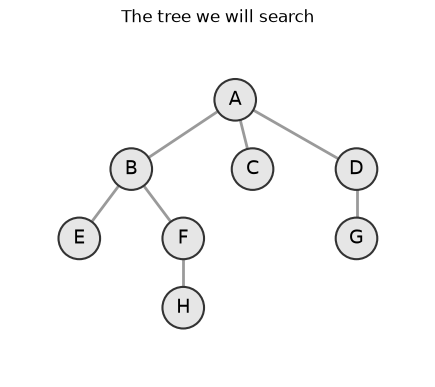

In [2]:
tree = {
    "A": ["B", "C", "D"],
    "B": ["E", "F"],
    "C": [],
    "D": ["G"],
    "E": [],
    "F": ["H"],
    "G": [],
    "H": [],
}

# where each node is drawn: (x, y)
tree_pos = {
    "A": (2.25, 3),
    "B": (0.75, 2), "C": (2.5, 2), "D": (4.0, 2),
    "E": (0.0, 1),  "F": (1.5, 1), "G": (4.0, 1),
    "H": (1.5, 0),
}

ROOT, TREE_GOAL = "A", "H"
show_structure(tree_pos, tree_edges(tree), "The tree we will search")

### The algorithm: BFS with a built-in queue

`deque` (pronounced "deck") comes from the `collections` module and is Python's standard double-ended queue.

* `queue.append(item)` adds an item at the right end.
* `queue.popleft()` removes and returns the item at the left end, which is the oldest one.
* `len(queue)` tells us how many items it holds.

Each item we store is a whole path such as `["A", "B"]`, so when we reach the goal we already know how we got there. The last element of a path is the current node.

You could also use a list and call `pop(0)`, but removing from the front of a list makes Python shift every other element. `popleft()` on a deque does not have that cost, which matters once the data gets big.

In [3]:
from collections import deque

def bfs_tree(tree, root, goal, trace=None):
    queue = deque()                       # Complete Code
    queue.append([root])                 # Complete Code
    visited = []

    while queue:                        # Complete Condition
        path = queue.popleft()                    # Complete Code
        node = path[-1]                      # the node we are standing on
        visited.append(node)

        if node == goal:                       # Complete Condition
            record(trace, node, [p[-1] for p in queue], visited)
            return path

        for child in tree[node]:             # Complete Code
            queue.append(path + [child])     # new path = old path plus the child

        record(trace, node, [p[-1] for p in queue], visited)

    return None                              # no path to the goal exists

### Run it

In [4]:
tree_trace = []
tree_path = bfs_tree(tree, ROOT, TREE_GOAL, tree_trace)

print("Path from", ROOT, "to", TREE_GOAL, ":", tree_path)
print("Order in which nodes were visited:", tree_trace[-1]["visited"])

Path from A to H : ['A', 'B', 'F', 'H']
Order in which nodes were visited: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']


BFS visited the nodes level by level: `A`, then `B C D`, then `E F G`, and finally `H`. It had to visit all of `C`, `D`, `E` and `G` before it reached `H`, which sits at the deepest level.

In a tree there is only one path to each node, so DFS and BFS return the same path here. What differs is the order of the visits and how many nodes had to be visited.

### Watch the BFS run on the tree

In [5]:
animate(tree_pos, tree_edges(tree), tree_trace, tree_path, "BFS on a tree", "queue", "(front is the leftmost box)")

---
## Example 2: BFS on a graph

A graph can contain cycles. In the graph below, `A - B - E - F - C - A` is a loop. If the search ignores that, it can walk around the loop forever. To prevent that we keep a record of every node we have visited and skip any node that comes up again.

Edges here go both ways, so in the dictionary `B` appears in the list of `A`, and `A` appears in the list of `B`.

### Build the graph

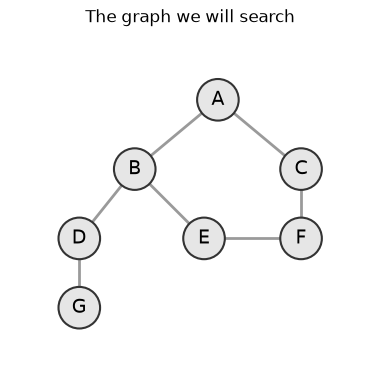

In [6]:
graph = {
    "A": ["B", "C"],
    "B": ["A", "D", "E"],
    "C": ["A", "F"],
    "D": ["B", "G"],
    "E": ["B", "F"],
    "F": ["C", "E"],
    "G": ["D"],
}

graph_pos = {
    "A": (2.0, 3),
    "B": (0.8, 2), "C": (3.2, 2),
    "D": (0.0, 1), "E": (1.8, 1), "F": (3.2, 1),
    "G": (0.0, 0),
}

START, GRAPH_GOAL = "A", "F"
show_structure(graph_pos, graph_edges(graph), "The graph we will search")

### The algorithm: BFS with a plain list as the queue

A Python list can act as a queue:

* `queue.append(item)` adds an item at the end.
* `queue.pop(0)` removes and returns the first item, which is the oldest one.

Compared with the tree version there are two new things.

* `visited` records which nodes we have already handled.
* After taking a path off the queue we check `if node in visited`. The same node can be added more than once before it is taken off, so this check is what makes the search skip repeats.

The queue in the animation will sometimes show grey boxes. Those are entries that were added earlier but whose node has since been visited by another route. They get skipped when they come out.

In [7]:
def bfs_graph(graph, start, goal, trace=None):
    queue = [[start]]                      # a list used as a queue
    visited = []

    while  queue :                   # Complete Condition
        path = queue.pop(0)                   # Complete Code
        node = path[-1]

        if node in visited:                # already handled through another route
            continue                      # Complete Code

        visited.append(node)                          # Complete Code

        if node == goal:                      # Complete Condition
            record(trace, node, [p[-1] for p in queue], visited)
            return path

        for neighbor in graph[node]:         # Complete Code
            if neighbor not in visited:  # Complete Code
                queue.append(path + [neighbor])

        record(trace, node, [p[-1] for p in queue], visited)

    return None

### Run it

In [8]:
graph_trace = []
graph_path = bfs_graph(graph, START, GRAPH_GOAL, graph_trace)

print("Path from", START, "to", GRAPH_GOAL, ":", graph_path)
print("Order in which nodes were visited:", graph_trace[-1]["visited"])
print("Number of nodes visited:", len(graph_trace[-1]["visited"]))

Path from A to F : ['A', 'C', 'F']
Order in which nodes were visited: ['A', 'B', 'C', 'D', 'E', 'F']
Number of nodes visited: 6


BFS returned `A -> C -> F`, which is two steps. That is the shortest path in this graph. BFS reaches every node at distance 1 before any node at distance 2, so the first time it reaches the goal it has used the fewest possible steps.

The price is that it visited several nodes along the way (`B`, `D`, `E`) that were not on the final path.

### Watch the BFS run on the graph

In [9]:
animate(graph_pos, graph_edges(graph), graph_trace, graph_path, "BFS on a graph", "queue", "(front is the leftmost box)")


## Summary

| | Tree | Graph |
|---|---|---|
| Can it loop forever? | No, there are no cycles | Yes, unless you track visited nodes |
| Needs `visited`? | No | Yes |
| Queue used here | `collections.deque` | plain `list` |
| Add / remove | `append()` / `popleft()` | `append()` / `pop(0)` |

BFS finds the path with the fewest steps when every edge counts the same. The cost is memory, because the queue can hold a whole level of the search at once.